In [1]:
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras import layers, models
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input

In [3]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    "Object Detection/Intel Image Classification",
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=(224, 224),
    batch_size=16
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    "Object Detection/Intel Image Classification",
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=(224, 224),
    batch_size=16
)

class_names = train_ds.class_names

print("Number of Classes:", len(class_names))
display(class_names)

Found 12632 files belonging to 6 classes.
Using 10106 files for training.
Found 12632 files belonging to 6 classes.
Using 2526 files for validation.
Number of Classes: 6


['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']

In [7]:
base = VGG16(
    weights = "Object Detection/vgg16_weights_tf_dim_ordering_tf_kernels_notop.h5",
    include_top=False,
    input_shape=(224 , 224 , 3)
)
base.trainable = False

In [13]:
model = models.Sequential([
    layers.Input(shape = (224,224,3)),
    layers.Lambda(preprocess_input),
    base,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128 , activation="relu"),
    layers.Dense(len(class_names) , activation="softmax")
    
])

In [17]:
model.compile(
    optimizer="adam",
    loss = "sparse_categorical_crossentropy",
    metrics = ["accuracy"]
)
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lambda_4 (Lambda)               │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,781,126 (56.39 MB)

 Trainable params: 66,438 (259.52 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [18]:
history = model.fit(
    train_ds.take(10) ,
    validation_data=test_ds.take(10),
    epochs = 3
)

Epoch 1/3


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


10/10 ━━━━━━━━━━━━━━━━━━━━ 33s 3s/step - accuracy: 0.3688 - loss: 2.4623 - val_accuracy: 0.6750 - val_loss: 1.0425
Epoch 2/3
10/10 ━━━━━━━━━━━━━━━━━━━━ 33s 3s/step - accuracy: 0.8125 - loss: 0.7400 - val_accuracy: 0.8125 - val_loss: 0.6092
Epoch 3/3
10/10 ━━━━━━━━━━━━━━━━━━━━ 33s 4s/step - accuracy: 0.8813 - loss: 0.3332 - val_accuracy: 0.7875 - val_loss: 0.7204


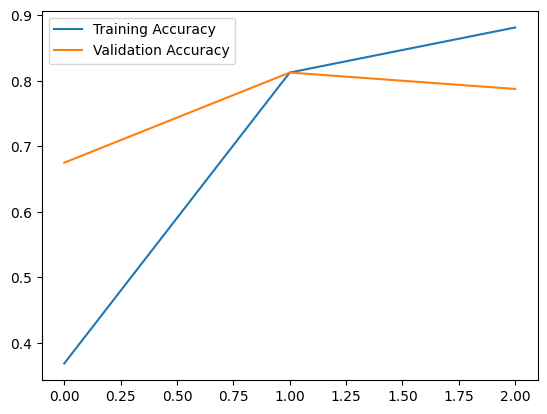

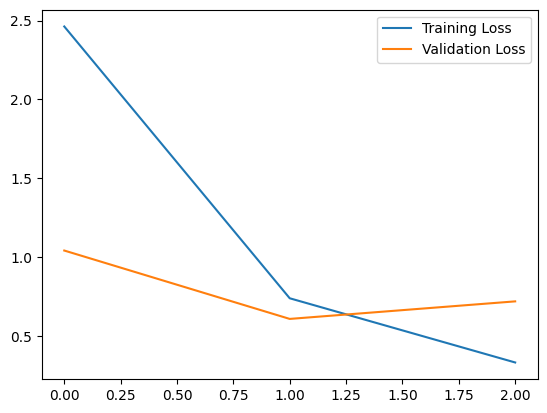

In [19]:
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.legend()
plt.show()

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.legend()
plt.show()

In [20]:
loss, accuracy = model.evaluate(test_ds)

print("Loss:", loss)
print("Accuracy:", accuracy)

158/158 ━━━━━━━━━━━━━━━━━━━━ 283s 2s/step - accuracy: 0.7910 - loss: 0.7020
Loss: 0.7019790410995483
Accuracy: 0.7909738421440125


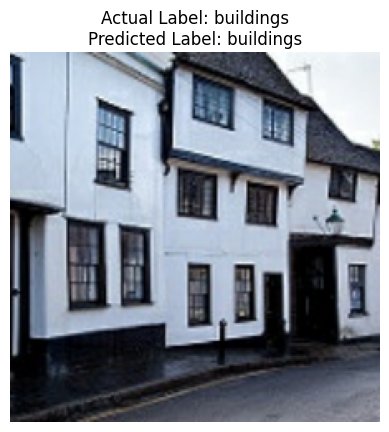

2026-11-02 15:06:08.267555: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


In [23]:
for images , label in test_ds.take(1):
    prediction = model.predict(images[:1] , verbose = 0)
    predicted = prediction.argmax(axis = 1)
    plt.imshow(images[0].numpy().astype("uint8"))
    plt.title(f"Actual Label: {class_names[label[0]]}\nPredicted Label: {class_names[predicted[0]]}")
    plt.axis("off")
    plt.show()

In [27]:
base.trainable = True
for layer in base.layers[:-6]:
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-5),loss="sparse_categorical_crossentropy", metrics=["accuracy"]
)    

history2 = model.fit(
    train_ds.take(10) , validation_data = test_ds.take(10) , epochs = 1
)

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


10/10 ━━━━━━━━━━━━━━━━━━━━ 41s 4s/step - accuracy: 0.9187 - loss: 0.2021 - val_accuracy: 0.8188 - val_loss: 0.5892


In [28]:
loss, accuracy = model.evaluate(test_ds)

print("Fine Tuned Loss:", loss)
print("Fine Tuned Accuracy:", accuracy)

158/158 ━━━━━━━━━━━━━━━━━━━━ 442s 3s/step - accuracy: 0.8044 - loss: 0.6691
Fine Tuned Loss: 0.6691327095031738
Fine Tuned Accuracy: 0.8044338822364807
